<a href="https://colab.research.google.com/github/cemileyazici2026-hub/ai-fotograf-arastirmasi/blob/main/Hafta6_Veri_Analizi_361526101_Cemile_Yazici.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## A. Veri Tanıtımı

**Araştırma konusu:** İnsanların gerçek fotoğraf ile yapay zekâ tarafından oluşturulan fotoğrafı ayırt etme başarısının incelenmesi.

**Veri kaynağı:** A (Mid)journey Through Reality araştırmasının açık veri seti.

**Veri dosyası:** `responses_task.csv`

**Veri türü:** Gerçek araştırma verisi; tahmini veri değildir.

**Veri kapsamı:** 11.170 kayıt ve 9 sütun.

**İncelenen sayısal değişken:** `ai_confidence_score`

**Birim: Yüzde (%); kaynakta 0–100% aralığında tanımlanmıştır.

**Değişkenin anlamı:** Katılımcıya gösterilen, algoritmanın fotoğrafın yapay zekâ tarafından oluşturulmasına ilişkin simüle edilmiş güven puanı.
**Veri setinin kaynak bağlantısı:**  
https://github.com/mirkocasu/a-mid-journey-through-reality

## B. Başlangıç

Bu çalışmada Python programlama dili kullanılmıştır. Veri analizi için Pandas, grafik oluşturmak için Matplotlib kütüphanelerinden yararlanılmıştır. `responses_task.csv` dosyası Pandas kullanılarak içe aktarılmıştır.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
df = pd.read_csv("responses_task.csv")

df.head()

,participant_id,variant,image_id,ground_truth,initial_response,had_doubt,ai_confidence_score,post_suggestion_action,effective_final_response
0,P0001,alpha,alpha_01,real,real,yes,86,change,AI
1,P0001,alpha,alpha_02,AI_magnific,real,no,88,change,AI
2,P0001,alpha,alpha_03,real,AI,no,78,confirm,AI
3,P0001,alpha,alpha_04,AI_midjourney,AI,no,74,change,real
4,P0001,alpha,alpha_05,AI_magnific,real,no,67,change,AI


In [ ]:
df = pd.read_csv("responses_task.csv")

df.head()

,participant_id,variant,image_id,ground_truth,initial_response,had_doubt,ai_confidence_score,post_suggestion_action,effective_final_response
0,P0001,alpha,alpha_01,real,real,yes,86,change,AI
1,P0001,alpha,alpha_02,AI_magnific,real,no,88,change,AI
2,P0001,alpha,alpha_03,real,AI,no,78,confirm,AI
3,P0001,alpha,alpha_04,AI_midjourney,AI,no,74,change,real
4,P0001,alpha,alpha_05,AI_magnific,real,no,67,change,AI


In [ ]:
df.shape

(11170, 9)

In [ ]:
df.isnull().sum()

,0
participant_id,0
variant,0
image_id,0
ground_truth,0
initial_response,0
had_doubt,0
ai_confidence_score,0
post_suggestion_action,0
effective_final_response,0


In [ ]:
df["ai_confidence_score"].describe()

,ai_confidence_score
count,11170.000000
mean,62.443868
std,29.552743
min,0.000000
25%,42.000000
50%,72.000000
75%,85.000000
max,99.000000


In [ ]:
df["ai_confidence_score"].agg(["sum", "mean", "min", "max"])

,ai_confidence_score
sum,697498.000000
mean,62.443868
min,0.000000
max,99.000000


## D. Grafik ve Sonuç Dosyaları

Bu bölümde veri setindeki fotoğraf türlerinin dağılımı, fotoğraf türlerine göre ortalama AI güven puanları ve ilk yanıt ile nihai yanıt doğruluk oranları grafiklerle incelenmiştir.

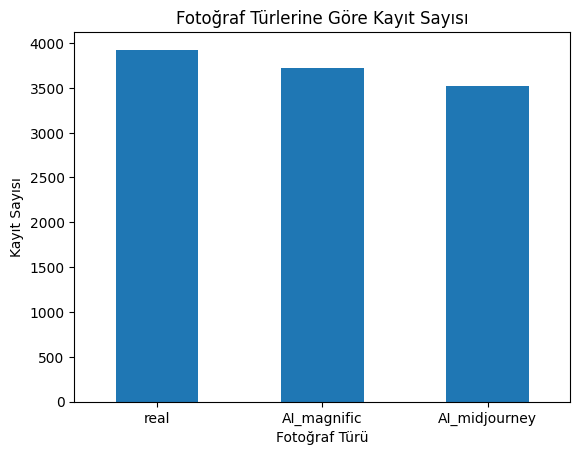

In [ ]:
df["ground_truth"].value_counts().plot(
    kind="bar",
    title="Fotoğraf Türlerine Göre Kayıt Sayısı"
)

plt.xlabel("Fotoğraf Türü")
plt.ylabel("Kayıt Sayısı")
plt.xticks(rotation=0)
plt.show()

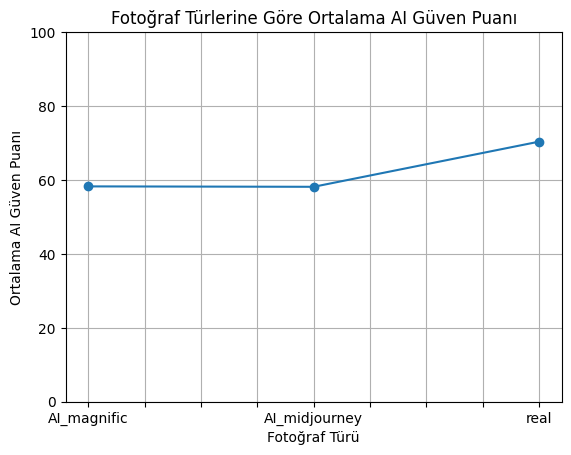

In [ ]:
ortalamalar = df.groupby("ground_truth")["ai_confidence_score"].mean()

ortalamalar.plot(
    kind="line",
    marker="o",
    ylim=(0, 100),
    title="Fotoğraf Türlerine Göre Ortalama AI Güven Puanı"
)

plt.xlabel("Fotoğraf Türü")
plt.ylabel("Ortalama AI Güven Puanı")
plt.grid()
plt.show()

In [ ]:
df.groupby("ground_truth")["ai_confidence_score"].mean()

,ai_confidence_score
ground_truth,
AI_magnific,58.222700
AI_midjourney,58.112057
real,70.328750


In [ ]:
df["correct"] = (
    (df["ground_truth"] == "real") &
    (df["effective_final_response"] == "real")
) | (
    (df["ground_truth"] != "real") &
    (df["effective_final_response"] == "AI")
)

df["correct"].value_counts()

,count
correct,
True,6352
False,4818


In [ ]:
print("Doğru cevap oranı:", round(df["correct"].mean() * 100, 2), "%")
print("Yanlış cevap oranı:", round((1 - df["correct"].mean()) * 100, 2), "%")

Doğru cevap oranı: 56.87 %
Yanlış cevap oranı: 43.13 %


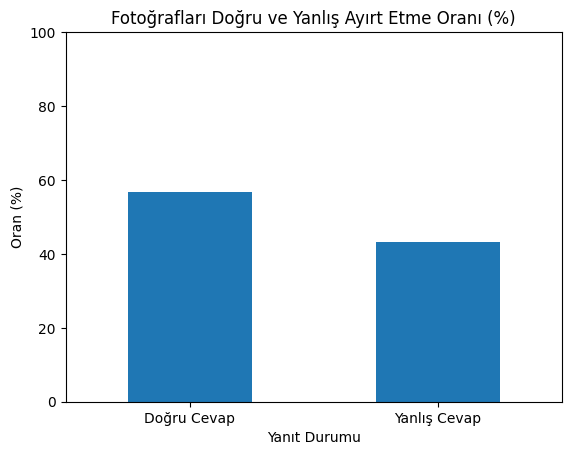

In [ ]:
oranlar = df["correct"].value_counts(normalize=True) * 100

oranlar.index = ["Doğru Cevap" if x else "Yanlış Cevap" for x in oranlar.index]

oranlar.plot(
    kind="bar",
    title="Fotoğrafları Doğru ve Yanlış Ayırt Etme Oranı (%)"
)

plt.xlabel("Yanıt Durumu")
plt.ylabel("Oran (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

In [ ]:
df["initial_correct"] = (
    ((df["ground_truth"] == "real") & (df["initial_response"] == "real")) |
    ((df["ground_truth"] != "real") & (df["initial_response"] == "AI"))
)

print("İlk yanıt doğruluğu:", round(df["initial_correct"].mean() * 100, 2), "%")
print("Nihai yanıt doğruluğu:", round(df["correct"].mean() * 100, 2), "%")

İlk yanıt doğruluğu: 59.63 %
Nihai yanıt doğruluğu: 56.87 %


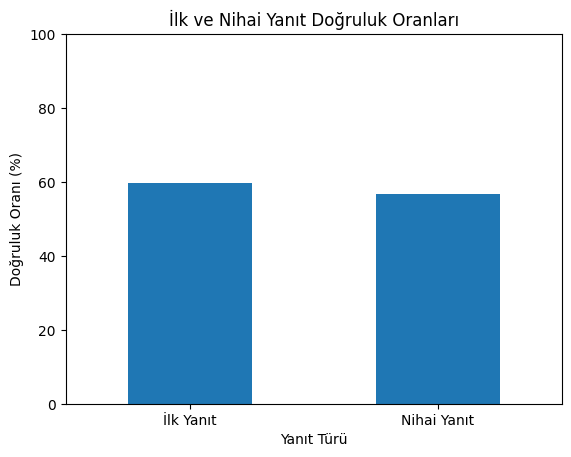

In [ ]:
dogruluk = pd.Series({
    "İlk Yanıt": df["initial_correct"].mean() * 100,
    "Nihai Yanıt": df["correct"].mean() * 100
})

dogruluk.plot(
    kind="bar",
    title="İlk ve Nihai Yanıt Doğruluk Oranları"
)

plt.xlabel("Yanıt Türü")
plt.ylabel("Doğruluk Oranı (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

## C. Sayısal Analiz Sonuçları

| Ölçüm | Sonuç | Birim |
|---|---:|---|
| Değerlendirme sayısı | 11.170 | Kayıt |
| Toplam AI güven puanı | 697.498 | Puan |
| Ortalama AI güven puanı | 62,44 | Puan |
| En düşük AI güven puanı | 0 | Puan |
| En yüksek AI güven puanı | 99 | Puan |
| İlk yanıt doğruluk oranı | %59,63 | Yüzde |
| Nihai yanıt doğruluk oranı | %56,87 | Yüzde |

**Veri niteliği:** Değerler açık erişimli araştırma veri setinden hesaplanmıştır; tahmini değildir.

## E. Akademik yorum

İncelenen veri setinde toplam 11.170 fotoğraf değerlendirmesi bulunmaktadır. Fotoğrafların nihai yanıtlara göre doğru ayırt edilme oranı %56,87, yanlış ayırt edilme oranı ise %43,13 olarak hesaplanmıştır. İlk yanıtların doğruluk oranı %59,63 iken nihai yanıtların doğruluk oranı %56,87 olmuştur. Bu sonuç, öneri sonrasında yapılan değişikliklerin doğruluk oranını artırmadığını ve oranın 2,76 yüzde puan azaldığını göstermektedir. Araştırma, katılımcıların fotoğrafları ayırt etme başarısını göstermektedir ancak tek başına bu değişimin nedenini açıklamamaktadır.


## F. Teslim Kontrolü

- [x] Veri seti yüklendi ve incelendi.
- [x] Toplam ve ortalama hesaplandı.
- [x] En az bir sütun ve bir çizgi grafik oluşturuldu.
- [x] İlk ve nihai yanıt doğruluk oranları hesaplandı.
- [x] Akademik yorum eklendi.
- [x] Veri kaynağı belirtildi.